# 2. Feature Mappings for Image Reconstruction

In [1]:
# Imports necessary libraries and performs folder cleanup.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import hashlib
from PIL import Image
from tqdm import tqdm
import matplotlib.pyplot as plt
import time
import os
import shutil
import imageio

artifacts_dir = 'runs-q2'
if os.path.exists(artifacts_dir):
    print(f"Removing old artifacts directory: {artifacts_dir}")
    shutil.rmtree(artifacts_dir)
print(f"Creating clean artifacts directory: {artifacts_dir}")
os.makedirs(artifacts_dir)

# Fix seed for reproducible randomization.
username = "sudhanva.joshi"
seed = int(hashlib.sha256(username.encode()).hexdigest(), 16) % (2**32)
print("Seed generated:", seed)
rng = np.random.default_rng(seed)
np.random.seed(seed) 

# Set plotting theme and helper functions.
sns.set_theme(context="paper", style="darkgrid",
              palette="magma", font="Nimbus Roman")

def plotinfo(title, x, y, userid=username):
    """Adds standard info and styling to a Matplotlib plot."""
    plt.text(0.95, -0.1, userid, ha="right", va="top",
             transform=plt.gca().transAxes, fontsize=10,
             color="gray", alpha=0.7)
    plt.title(title, fontsize=14, fontweight='bold')
    plt.xlabel(x, fontsize=12)
    plt.ylabel(y, fontsize=12)

def coordplot(ax, title, x_label, y_label):
    """Helper function to set title and labels for subplots."""
    ax.set_title(title)
    ax.set_xlabel(x_label)
    ax.set_ylabel(y_label)

Removing old artifacts directory: runs-q2
Creating clean artifacts directory: runs-q2
Seed generated: 1027714457


#### Model Classes Import

In [2]:
class Linear:
    def __init__(self, input_dim, output_dim, activation):
        self.activation = activation()
        self.biases = np.zeros((output_dim, 1))

        # Weight initialization
        if activation.__name__ == "ReLU":
            scale = np.sqrt(2. / input_dim)
        else: 
            scale = np.sqrt(1. / input_dim)
        self.weights = rng.standard_normal(size=(output_dim, input_dim)) * scale
        
        # Storing cumulative gradients
        self.grad_weights = np.zeros_like(self.weights)
        self.grad_biases = np.zeros_like(self.biases)

        # Add new variables for Adam optimizer state
        self.m_weights = np.zeros_like(self.weights)
        self.v_weights = np.zeros_like(self.weights)
        self.m_biases = np.zeros_like(self.biases)
        self.v_biases = np.zeros_like(self.biases)

    def forward(self, x):
        self.input = x
        self.z = np.dot(self.weights, self.input) + self.biases
        self.output = self.activation.forward(self.z)
        return self.output

    def backward(self, grad_output):
        grad_z = self.activation.backward(grad_output)
        
        grad_w = np.dot(grad_z, self.input.T)
        grad_b = np.sum(grad_z, axis=1, keepdims=True)
        
        self.grad_weights += grad_w
        self.grad_biases += grad_b
        
        grad_input = np.dot(self.weights.T, grad_z)
        return grad_input
    
class Identity:
    def forward(self, x):
        return x

    def backward(self, grad_output):
        return grad_output

class ReLU:
    def forward(self, x):
        self.input = x
        return np.maximum(0, x)

    def backward(self, grad_output):
        grad_input = grad_output.copy()
        grad_input[self.input <= 0] = 0
        return grad_input

class Tanh:
    def forward(self, x):
        self.output = np.tanh(x)
        return self.output

    def backward(self, grad_output):
        return grad_output * (1 - self.output**2)
            
class Sigmoid:
    def forward(self, x):
        x = np.clip(x, -500, 500)
        self.output = 1 / (1 + np.exp(-x))
        return self.output

    def backward(self, grad_output):
        return grad_output * self.output * (1 - self.output)
    
def mse_loss(y_pred, y_true):
    y_true = np.array(y_true).reshape(y_pred.shape)
    loss = np.mean((y_pred - y_true)**2)
    grad = 2 * (y_pred - y_true) / y_true.size
    return loss, grad

def bce_loss(y_pred, y_true):
    y_true = np.array(y_true).reshape(y_pred.shape)
    # Clip predictions to avoid log(0)
    epsilon = 1e-15
    y_pred = np.clip(y_pred, epsilon, 1 - epsilon)
    loss = -np.mean(y_true * np.log(y_pred) + (1 - y_true) * np.log(1 - y_pred))
    grad = (y_pred - y_true) / (y_pred * (1 - y_pred) * y_true.size)

    return loss, grad

class Model:
    def __init__(self, layers, loss_fn='mse'):
        self.layers = layers
        if loss_fn == 'mse':
            self.loss_function = mse_loss
        elif loss_fn == 'bce':
            self.loss_function = bce_loss
        else:
            raise ValueError("Unsupported loss function. Use 'mse' or 'bce'.")
        
        self.t = 0
        
    def forward(self, x):
        for layer in self.layers:
            x = layer.forward(x)
        return x

    def backward(self, grad):
        for layer in reversed(self.layers):
            grad = layer.backward(grad)

    def train(self, x, y):
        y_pred = self.forward(x.T) 
        loss, grad_loss = self.loss_function(y_pred, y.T)
        self.backward(grad_loss)
        return loss

    def zero_grad(self):
        for layer in self.layers:
            layer.grad_weights.fill(0)
            layer.grad_biases.fill(0)

    def update(self, learning_rate, beta1=0.9, beta2=0.999, epsilon=1e-8):
        """
        Updates the model's parameters using the Adam optimizer.
        """
        self.t += 1
        for layer in self.layers:
            # Update biased first moment estimate (like momentum)
            layer.m_weights = beta1 * layer.m_weights + (1 - beta1) * layer.grad_weights
            layer.m_biases = beta1 * layer.m_biases + (1 - beta1) * layer.grad_biases

            # Update biased second raw moment estimate (adaptive learning rate part)
            layer.v_weights = beta2 * layer.v_weights + (1 - beta2) * (layer.grad_weights**2)
            layer.v_biases = beta2 * layer.v_biases + (1 - beta2) * (layer.grad_biases**2)

            # Compute bias-corrected moment estimates
            m_hat_w = layer.m_weights / (1 - beta1**self.t)
            m_hat_b = layer.m_biases / (1 - beta1**self.t)
            v_hat_w = layer.v_weights / (1 - beta2**self.t)
            v_hat_b = layer.v_biases / (1 - beta2**self.t)

            # Update weights and biases
            layer.weights -= learning_rate * m_hat_w / (np.sqrt(v_hat_w) + epsilon)
            layer.biases -= learning_rate * m_hat_b / (np.sqrt(v_hat_b) + epsilon)

        self.zero_grad()

    def predict(self, x):
        prediction = self.forward(x.T)
        return prediction.T

    def save_to(self, path):
        params = {f'w{i}': layer.weights for i, layer in enumerate(self.layers)}
        params.update({f'b{i}': layer.biases for i, layer in enumerate(self.layers)})
        np.savez(path, **params)
        print(f"Model saved to {path}")

    def load_from(self, path):
        data = np.load(path)
        for i, layer in enumerate(self.layers):
            if f'w{i}' not in data or f'b{i}' not in data:
                raise ValueError(f"File {path} is missing parameters for layer {i}.")
            
            w_shape = data[f'w{i}'].shape
            b_shape = data[f'b{i}'].shape
            
            if w_shape != layer.weights.shape or b_shape != layer.biases.shape:
                raise ValueError(
                    f"Dimension mismatch in layer {i}. "
                    f"Expected W:{layer.weights.shape}, B:{layer.biases.shape}; "
                    f"Got W:{w_shape}, B:{b_shape}."
                )
            
            layer.weights = data[f'w{i}']
            layer.biases = data[f'b{i}']
        print(f"Model loaded from {path}")

# Other Helper Functions

def calculate_accuracy(model, dataset):
    """Calculates accuracy on the entire dataset in a vectorized manner."""
    all_x = np.array([sample[0] for sample in dataset.all_samples])
    all_y_true = np.array([sample[1] for sample in dataset.all_samples]).reshape(-1, 1)

    all_y_pred = model.predict(all_x) 

    predictions = (all_y_pred > 0.5).astype(int) 
    accuracy = np.mean(predictions == all_y_true)
    
    return accuracy

def count_parameters(model):
    """Counts the total number of trainable parameters in the model."""
    total_params = 0
    for layer in model.layers:
        total_params += layer.weights.size + layer.biases.size
    return total_params

def train_loop(model, dataset, epochs, batch_size, learning_rate, run_folder, 
    patience=10, relative_loss_threshold=0.01):
    """Implements the core training logic with early stopping."""
    start_time = time.time()
    os.makedirs(run_folder, exist_ok=True)
    
    losses, epoch_losses = [], []
    samples_seen = 0

    for epoch in range(epochs):
        shuffled_data = dataset.get_shuffled_samples()
        batch_iterator = (shuffled_data[i:i + batch_size] for i in range(0, len(shuffled_data), batch_size))
        num_batches = (len(shuffled_data) + batch_size - 1) // batch_size
        progress_bar = tqdm(enumerate(batch_iterator), total=num_batches, desc=f"Epoch {epoch+1}/{epochs}", leave=False)
        current_epoch_loss = 0
        
        for i, batch in progress_bar:
            if not batch: continue
            X_batch, Y_batch = zip(*batch)
            X_batch, Y_batch = np.array(X_batch), np.array(Y_batch)
            
            batch_loss = model.train(X_batch, Y_batch)
            model.update(learning_rate)
            
            losses.append(batch_loss)
            samples_seen += len(batch)
            current_epoch_loss += batch_loss * len(batch)

        avg_epoch_loss = current_epoch_loss / len(shuffled_data)
        epoch_losses.append(avg_epoch_loss)
        
        # Early Stopping Logic
        if epoch >= patience:
            last_patience_epoch_loss = epoch_losses[epoch - patience]
            if avg_epoch_loss >= (1 - relative_loss_threshold) * last_patience_epoch_loss:
                print(f"\nEarly stopping triggered at epoch {epoch + 1}.")
                break
            
    time_taken = time.time() - start_time
    print(f"Epoch {epoch+1} complete. Total samples seen: {samples_seen}. Time: {time_taken:.2f}s.")
    
    # Plotting Loss
    plt.figure(figsize=(12, 6))
    loss_df = pd.DataFrame({"Samples Seen": np.arange(len(losses)) * batch_size, "Loss": losses})
    window_size = 50
    loss_df['Smoothed Loss'] = loss_df['Loss'].rolling(window=window_size, min_periods=1).mean()
    sns.lineplot(data=loss_df, x="Samples Seen", y="Loss", alpha=0.4, label='Raw Loss (per batch)')
    sns.lineplot(data=loss_df, x="Samples Seen", y="Smoothed Loss", label=f'Smoothed Trend (window={window_size})')
    plt.legend()
    plotinfo("Loss vs. Samples Seen", "No. of Samples Seen", "Loss")
    plot_path = os.path.join(run_folder, "loss_plot.png")
    plt.savefig(plot_path, bbox_inches="tight", dpi=300)
    plt.show()
    plt.close()
    
    print("Saving final model.")
    model_path = os.path.join(run_folder, "final_model.npz")
    # model.save_to(model_path) # save_to/load_from methods are not defined in the provided code
    
    final_loss = epoch_losses[-1] if epoch_losses else None
    print(f"Model has {count_parameters(model)} trainable parameters.")
    print(f"Final Loss: {final_loss}")
    
    return model, run_folder, samples_seen, time_taken, epoch_losses


## 2.1 Setup and Visualization

In [3]:
# --- Data Handling and Feature Engineering ---
def load_image(path, size=(256, 256)):
    """Loads, resizes, and normalizes an image to [0, 1]."""
    img = Image.open(path).resize(size)
    img_array = np.array(img, dtype=np.float32) / 255.0
    if len(img_array.shape) == 3 and img_array.shape[2] == 1:
        img_array = img_array.squeeze(-1) # Handle grayscale with channel dim
    return img_array

def create_coordinate_grid(height, width):
    """Creates a normalized [0, 1] coordinate grid."""
    xs = np.linspace(0, 1, width, dtype=np.float32)
    ys = np.linspace(0, 1, height, dtype=np.float32)
    return np.stack(np.meshgrid(xs, ys), -1).reshape(-1, 2)

def save_reconstruction(pixels, height, width, path):
    """Saves a reconstructed image from pixel values."""
    shape = (height, width, -1)
    img_array = (np.clip(pixels, 0.0, 1.0) * 255).astype(np.uint8)
    Image.fromarray(img_array.reshape(shape).squeeze()).save(path)

## 2.2 Feature Expansions

In [4]:
# --- Feature Expansion Functions ---
def get_raw(coords):
    """Raw mapping: returns coordinates unchanged."""
    return coords

def get_polynomial(coords, order=5):
    """Polynomial mapping with cross-terms."""
    x, y = coords[:, 0:1], coords[:, 1:2]
    features = []
    for i in range(order + 1):
        for j in range(order - i + 1):
            if i == 0 and j == 0: continue
            features.append((x**i) * (y**j))
    return np.concatenate(features, axis=1)

def get_fourier(coords, freq=10):
    """Fourier mapping with exponential frequency bands."""
    x, y = coords[:, 0:1], coords[:, 1:2]
    features = [coords]
    freqs = 2**np.arange(freq) * np.pi
    for f in freqs:
        features.extend([np.sin(f * x), np.cos(f * x), np.sin(f * y), np.cos(f * y)])
    return np.concatenate(features, axis=1)

## 2.3 Normalization and Modular MLP

In [5]:
class Modular_Dataloader:
    """A modular dataloader for image reconstruction."""
    def __init__(self, img_path, image_type, method, order=None, freq=None, size=(256, 256)):
        img_array = load_image(img_path, size)
        self.height, self.width = img_array.shape[:2]
        
        coords = create_coordinate_grid(self.height, self.width)
        self.pixels = img_array.reshape(-1, 1 if image_type == "Gray" else 3)
        
        # Apply feature mapping
        mapping_fn = {'Raw': get_raw, 'Polynomial': get_polynomial, 'Fourier': get_fourier}
        mapping_args = {'order': order} if method == 'Polynomial' else {'freq': freq}
        self.features = mapping_fn[method](coords, **{k:v for k,v in mapping_args.items() if v is not None})
        
        # Normalize features [cite: 198]
        if method == "Polynomial":
            mean, std = np.mean(self.features, 0), np.std(self.features, 0)
            self.features = (self.features - mean) / np.where(std == 0, 1, std)

        self.all_samples = list(zip(self.features, self.pixels))
        print(f"Dataloader: {method}. Input dim: {self.features.shape[1]}. Samples: {len(self.all_samples)}")

    def get_shuffled_samples(self):
        rng.shuffle(self.all_samples)
        return self.all_samples

## 2.4 Training and Comparison

In [6]:
def train_reconstruction(model, dataloader, epochs, batch_size, 
                        learning_rate, run_folder, save_every=1):
    """
    Training loop that saves intermediate images and returns per-epoch losses.
    """
    start_time = time.time()
    os.makedirs(run_folder, exist_ok=True)
    
    # This will store the average loss for each epoch
    epoch_losses = [] 

    for epoch in range(epochs):
        shuffled_data = dataloader.get_shuffled_samples()
        batch_iterator = (shuffled_data[i:i+batch_size] for i in range(0, len(shuffled_data), batch_size))
        progress_bar = tqdm(batch_iterator, total=len(shuffled_data)//batch_size, 
                            desc=f"Epoch {epoch+1}/{epochs}", leave=False)
        
        batch_losses = []
        for batch in progress_bar:
            if not batch: continue
            X_batch, Y_batch = map(np.array, zip(*batch))
            loss = model.train(X_batch, Y_batch)
            model.update(learning_rate)
            batch_losses.append(loss)
        
        # Calculate and store the average loss for the completed epoch
        avg_epoch_loss = np.mean(batch_losses)
        epoch_losses.append(avg_epoch_loss)

        # [cite_start]Save reconstruction image for the current epoch [cite: 234]
        if (epoch + 1) % save_every == 0 or epoch == epochs - 1:
            full_pred = model.predict(dataloader.features)
            save_reconstruction(full_pred, dataloader.height, dataloader.width, 
                                os.path.join(run_folder, f"epoch_{epoch+1:03d}.png"))
    
    total_time = time.time() - start_time
    print(f"Run complete. Final Loss: {epoch_losses[-1]:.6f}, Time: {total_time:.2f}s")
    
    # Return the list of all epoch losses
    return epoch_losses, total_time

In [7]:
IMAGE_CONFIG = {
    'smiley': {'path': 'data/Q2/smiley.png', 'type': 'Gray', 'epochs': 50, 'output_dim': 1},
    'cat': {'path': 'data/Q2/cat.jpg', 'type': 'RGB', 'epochs': 150, 'output_dim': 3}
}
METHOD_CONFIG = {
    'Raw': {'method': 'Raw'},
    'Polynomial (O=5)': {'method': 'Polynomial', 'order': 5},
    'Polynomial (O=15)': {'method': 'Polynomial', 'order': 15},
    'Polynomial (O=25)': {'method': 'Polynomial', 'order': 25},
    'Fourier (F=5)': {'method': 'Fourier', 'freq': 5},
    'Fourier (F=15)': {'method': 'Fourier', 'freq': 15},
    'Fourier (F=25)': {'method': 'Fourier', 'freq': 25},
}
LEARNING_RATE, BATCH_SIZE = 2.5e-4, 1024

# Dictionaries to store artifacts for table and GIFs
results = []
gif_folders = {'smiley': {}, 'cat': {}}
all_epoch_losses = {'smiley': {}, 'cat': {}}

for img_name, img_params in IMAGE_CONFIG.items():
    for method_name, method_params in METHOD_CONFIG.items():
        print(f"\n Running: Image='{img_name}', Method='{method_name}': ")
        dataloader = Modular_Dataloader(img_path=img_params['path'], image_type=img_params['type'], **method_params)
        
        input_dim = dataloader.features.shape[1]
        model = Model([
            Linear(input_dim, 256, ReLU), Linear(256, 256, ReLU),
            Linear(256, 256, ReLU), Linear(256, img_params['output_dim'], Sigmoid)
        ])
        
        run_folder = os.path.join(artifacts_dir, f"{img_name}_{method_name.replace(' ', '')}")
        
        # Train the model, saving an image every epoch for the GIFs
        epoch_losses, total_time = train_reconstruction(
            model, dataloader, img_params['epochs'], BATCH_SIZE, LEARNING_RATE, run_folder, save_every=1
        )

        # Store results for the final table
        results.append({
            'Image': img_name, 'Method': method_name, 'Final Loss': epoch_losses[-1],
            'Epoch Time (s)': total_time / img_params['epochs'],
            'Input Dimension': input_dim, 'Total Parameters': count_parameters(model)
        })
        
        # Store artifacts needed for GIF generation
        gif_folders[img_name][method_name] = run_folder
        all_epoch_losses[img_name][method_name] = epoch_losses

results_df = pd.DataFrame(results)
print("\nFinal Results Summary.")
print(results_df.to_string())


 Running: Image='smiley', Method='Raw': 
Dataloader: Raw. Input dim: 2. Samples: 65536


Run complete. Final Loss: 0.007767, Time: 337.53s

 Running: Image='smiley', Method='Polynomial (O=5)': 
Dataloader: Polynomial. Input dim: 20. Samples: 65536


Run complete. Final Loss: 0.005452, Time: 361.23s

 Running: Image='smiley', Method='Polynomial (O=15)': 
Dataloader: Polynomial. Input dim: 135. Samples: 65536


Run complete. Final Loss: 0.005593, Time: 385.64s

 Running: Image='smiley', Method='Polynomial (O=25)': 
Dataloader: Polynomial. Input dim: 350. Samples: 65536


Run complete. Final Loss: 0.005752, Time: 364.70s

 Running: Image='smiley', Method='Fourier (F=5)': 
Dataloader: Fourier. Input dim: 22. Samples: 65536


Run complete. Final Loss: 0.003694, Time: 333.34s

 Running: Image='smiley', Method='Fourier (F=15)': 
Dataloader: Fourier. Input dim: 62. Samples: 65536


... (5 outputs left out)

Run complete. Final Loss: 0.005427, Time: 827.08s

 Running: Image='cat', Method='Fourier (F=5)': 
Dataloader: Fourier. Input dim: 22. Samples: 65536


Run complete. Final Loss: 0.001518, Time: 1240.16s

 Running: Image='cat', Method='Fourier (F=15)': 
Dataloader: Fourier. Input dim: 62. Samples: 65536


Run complete. Final Loss: 0.000397, Time: 475.01s

 Running: Image='cat', Method='Fourier (F=25)': 
Dataloader: Fourier. Input dim: 102. Samples: 65536


Run complete. Final Loss: 0.000379, Time: 477.24s

Final Results Summary.
     Image             Method  Final Loss  Epoch Time (s)  Input Dimension  Total Parameters
0   smiley                Raw    0.007767        6.750670                2            132609
1   smiley   Polynomial (O=5)    0.005452        7.224549               20            137217
2   smiley  Polynomial (O=15)    0.005593        7.712850              135            166657
3   smiley  Polynomial (O=25)    0.005752        7.294081              350            221697
4   smiley      Fourier (F=5)    0.003694        6.666724               22            137729
5   smiley     Fourier (F=15)    0.001681        7.210819               62            147969
6   smiley     Fourier (F=25)    0.000939        7.617201              102            158209
7      cat                Raw    0.008762        5.926068                2            133123
8      cat   Polynomial (O=5)    0.004012        4.754602               20            137

In [8]:
def create_comparison_gif(image_name, total_epochs, methods_to_plot, 
                          folders_dict, losses_dict, output_path):
    """
    Creates a 1x3 subplot GIF showing image reconstruction and an evolving loss curve.
    """
    print(f"\n Creating GIF for '{image_name}'.")
    frames = []
    fig, axes = plt.subplots(1, 3, figsize=(18, 6))

    for epoch in range(1, total_epochs + 1):
        fig.suptitle(f'{image_name.capitalize()} Reconstruction\nEpoch {epoch}/{total_epochs}', 
                     fontsize=16, y=0.95)
        
        for i, method_name in enumerate(methods_to_plot):
            ax = axes[i]
            ax.clear() # Clear previous frame's content
            ax.set_xticks([])
            ax.set_yticks([])

            # 1. Display the reconstructed image
            folder = folders_dict[method_name]
            img_path = os.path.join(folder, f"epoch_{epoch:03d}.png")
            if os.path.exists(img_path):
                ax.imshow(imageio.imread(img_path), cmap='gray' if 'smiley' in image_name else None)
            ax.set_title(method_name)

            # 2. Overlay the loss curve plot
            inset_ax = ax.inset_axes([0.0, 0.7, 0.4, 0.3], facecolor='w', alpha=0.7)
            losses = losses_dict[method_name]
            inset_ax.plot(range(1, epoch + 1), losses[:epoch], color='dodgerblue')
            
            inset_ax.set_title("Loss Curve", fontsize=8)
            inset_ax.set_xlim(1, total_epochs)
            if losses:
                inset_ax.set_ylim(0, max(losses) * 1.1)
            inset_ax.tick_params(axis='both', which='major', labelsize=6)
            inset_ax.grid(True, linestyle='--', alpha=0.6)
            
        plt.text(0.95, -0.1, username, ha="right", va="top",
             transform=plt.gca().transAxes, fontsize=10,
             color="gray", alpha=0.7)
        fig.canvas.draw()
        rgba_buffer = fig.canvas.buffer_rgba()
        frame = np.array(rgba_buffer, dtype=np.uint8).reshape(fig.canvas.get_width_height()[::-1] + (4,))
        frames.append(frame[:, :, :3]) # Keep only the RGB channels
    plt.close(fig)
    imageio.mimsave(output_path, frames, fps=15)
    print(f"GIF saved to {output_path}")


gif_methods_to_plot = ['Raw', 'Polynomial (O=25)', 'Fourier (F=25)']

# Generate Smiley GIF
create_comparison_gif(
    image_name='smiley',
    total_epochs=IMAGE_CONFIG['smiley']['epochs'],
    methods_to_plot=gif_methods_to_plot,
    folders_dict=gif_folders['smiley'],
    losses_dict=all_epoch_losses['smiley'],
    output_path=os.path.join(artifacts_dir, 'smiley_comparison.gif')
)

# Generate Cat GIF
create_comparison_gif(
    image_name='cat',
    total_epochs=IMAGE_CONFIG['cat']['epochs'],
    methods_to_plot=gif_methods_to_plot,
    folders_dict=gif_folders['cat'],
    losses_dict=all_epoch_losses['cat'],
    output_path=os.path.join(artifacts_dir, 'cat_comparison.gif')
)


 Creating GIF for 'smiley'.


/tmp/ipykernel_325461/1880981029.py:24: DeprecationWarning: Starting with ImageIO v3 the behavior of this function will switch to that of iio.v3.imread. To keep the current behavior (and make this warning disappear) use `import imageio.v2 as imageio` or call `imageio.v2.imread` directly.
  ax.imshow(imageio.imread(img_path), cmap='gray' if 'smiley' in image_name else None)


GIF saved to runs-q2/smiley_comparison.gif

 Creating GIF for 'cat'.
GIF saved to runs-q2/cat_comparison.gif


## 2.5 Reconstruction on Blurred Images

Standard MLPs struggle to learn high-frequency functions, a phenomenon known as **spectral bias**. They are inherently biased towards learning low-frequency signals, which is why a model using raw coordinates (`BASE`) produces blurry reconstructions of sharp images; it simply cannot capture the high-frequency details like edges and textures.

Since the image features's RGB spectra can be represented in terms of the **Fourier Domain**, we use the **Fourier series approximation** of a kernel function to approximate the 'signal' *(in this case, the image RGB frequencies)*. 

Generally, a Fourier series is a way to represent a periodic function *(features in this case)* as a sum of sine and cosine functions. The approximation of a signal is achieved by summing the first few terms of this series, as the coefficients of the Fourier series decay to zero for real periodic signals.

 The most common form is the trigonometric Fourier series. For a periodic function *f(x)* with a period of 2L, the equation is: 

 $$
 f(x) = \frac{a_0}{2} + \sum_{n=1}^{\infty} (a_n \cos(\frac{n\pi x}{L}) + b_n \sin(\frac{n\pi x}{L}))
 $$ 

 **Where the coefficients are:** 
 
 * **a₀:** This is the average value of the function over one period. 
  $$
  a_0 = \frac{1}{L} \int_{-L}^{L} f(x) \,dx
  $$ 

 * **aₙ:** These are the cosine coefficients. 
  $$
  a_n = \frac{1}{L} \int_{-L}^{L} f(x) \cos(\frac{n\pi x}{L}) \,dx
  $$ 

 * **bₙ:** These are the sine coefficients. 
  $$
  b_n = \frac{1}{L} \int_{-L}^{L} f(x) \sin(\frac{n\pi x}{L}) \,dx
  $$ 


The vectors $b_j$ act as Fourier basis frequencies, and the scalars $a_j$ are their corresponding coefficients. 

The Fourier feature mapping, which transforms the input coordinates `v` uses a set of sinusoids before feeding them into the network, defined as:

$$
\gamma(v)=[a_{1}\cos(2\pi b_{1}^{T}v),a_{1}\sin(2\pi b_{1}^{T}v),...,a_{m}\cos(2\pi b_{m}^{T}v),a_{m}\sin(2\pi b_{m}^{T}v)]^{T}
$$ 

By providing the network with these explicit frequency components, it can more easily combine them to approximate the complex frequency spectrum (i.e., the Fourier transform) of the target image, enabling it to learn high-frequency details.

Gaussian blur acts as a **low-pass filter** that removes high-frequency details from an image.

* **Sharp Images**: The `FOURIER` model excels because it can represent the high-frequency content that the `BASE` model cannot due to spectral bias. The performance gap is large.
* **Blurred Images**: As blur increases, the target image loses its high-frequency content. The task becomes easier for the low-frequency-biased `BASE` model, and the high-frequency advantage of the `FOURIER` model becomes less relevant. Consequently, their reconstruction loss values converge.


 Processing Blurred Image: blur_0.png
  - Method: Raw
Dataloader: Raw. Input dim: 2. Samples: 65536


Epoch 100 complete. Total samples seen: 6553600. Time: 55.71s.


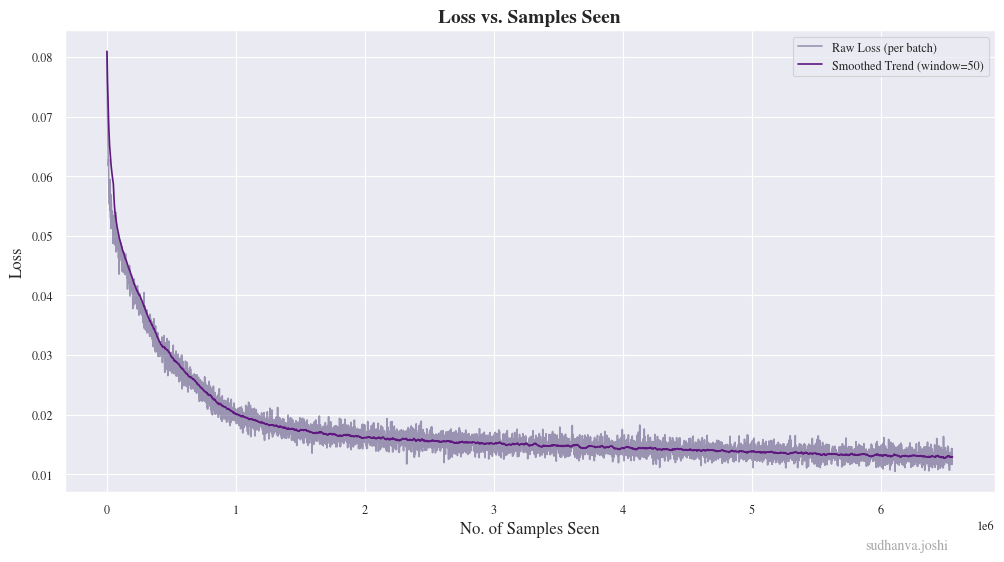

Saving final model.
Model has 17283 trainable parameters.
Final Loss: 0.012888299202583295
  - Method: Fourier
Dataloader: Fourier. Input dim: 22. Samples: 65536


Epoch 100 complete. Total samples seen: 6553600. Time: 55.14s.


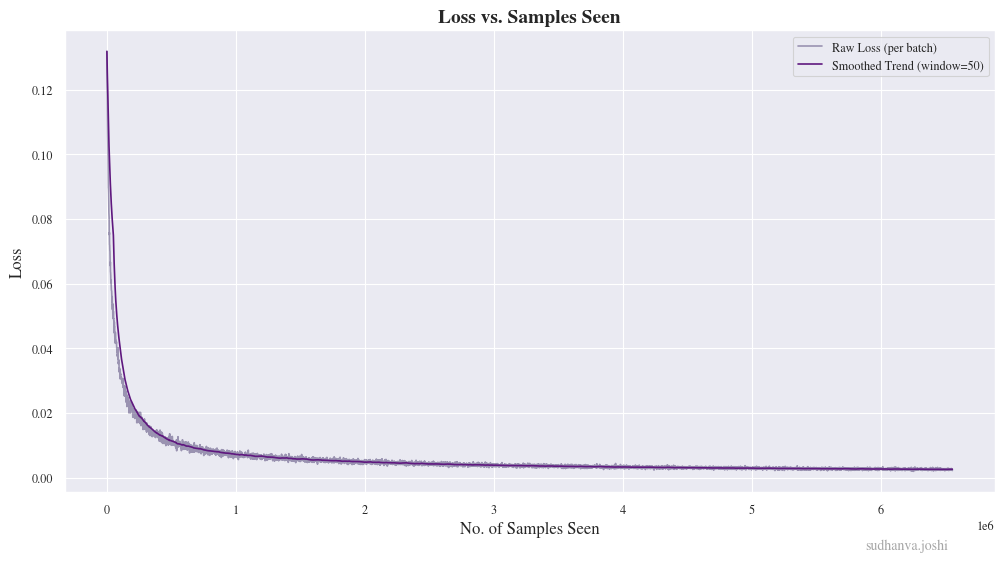

Saving final model.
Model has 19843 trainable parameters.
Final Loss: 0.002519920028488398

 Processing Blurred Image: blur_1.png
  - Method: Raw
Dataloader: Raw. Input dim: 2. Samples: 65536


Epoch 100 complete. Total samples seen: 6553600. Time: 47.36s.


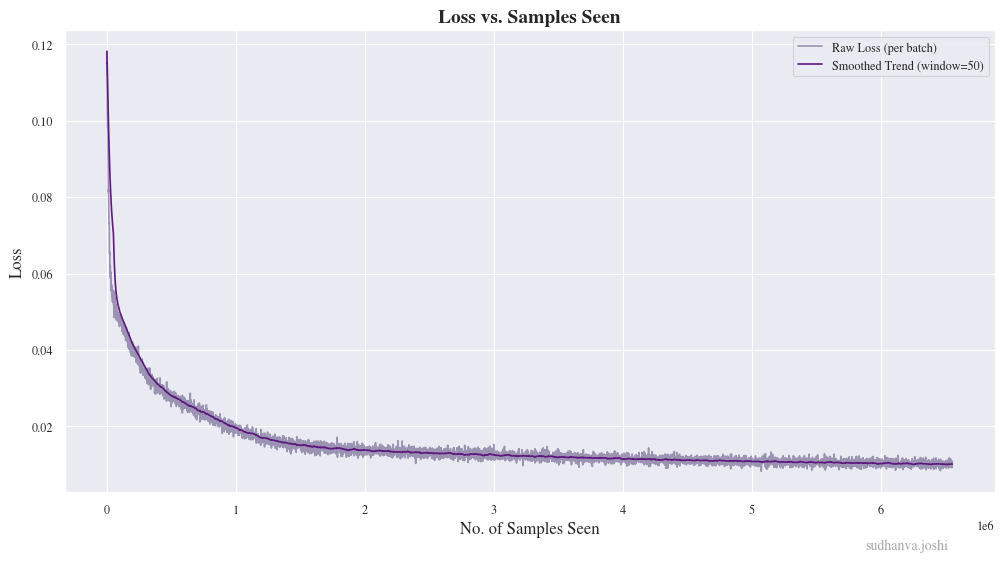

Saving final model.
Model has 17283 trainable parameters.
Final Loss: 0.01008428326515656
  - Method: Fourier
Dataloader: Fourier. Input dim: 22. Samples: 65536


Epoch 100 complete. Total samples seen: 6553600. Time: 52.84s.


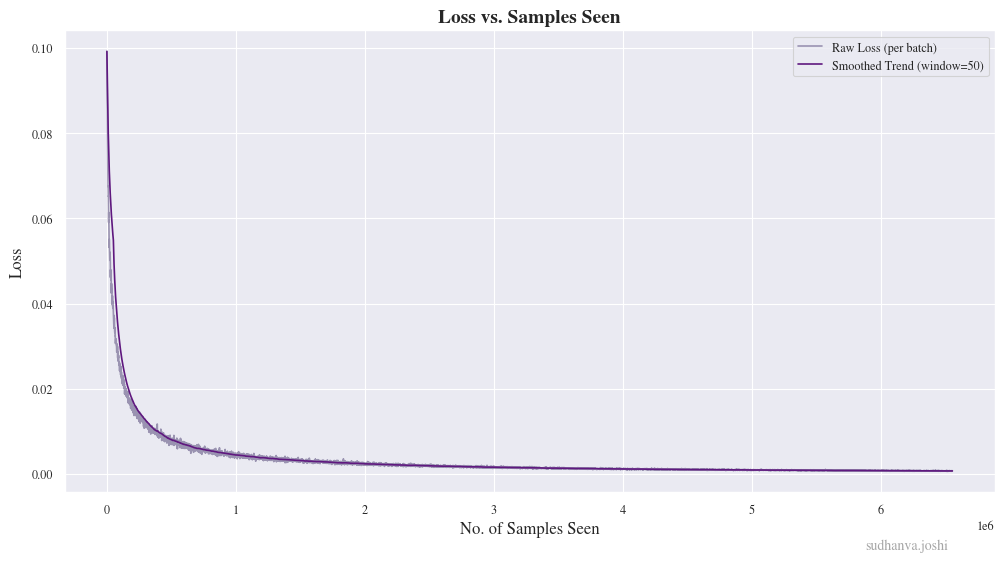

Saving final model.
Model has 19843 trainable parameters.
Final Loss: 0.0007167329793282104

 Processing Blurred Image: blur_2.png
  - Method: Raw
Dataloader: Raw. Input dim: 2. Samples: 65536


Epoch 100 complete. Total samples seen: 6553600. Time: 43.20s.


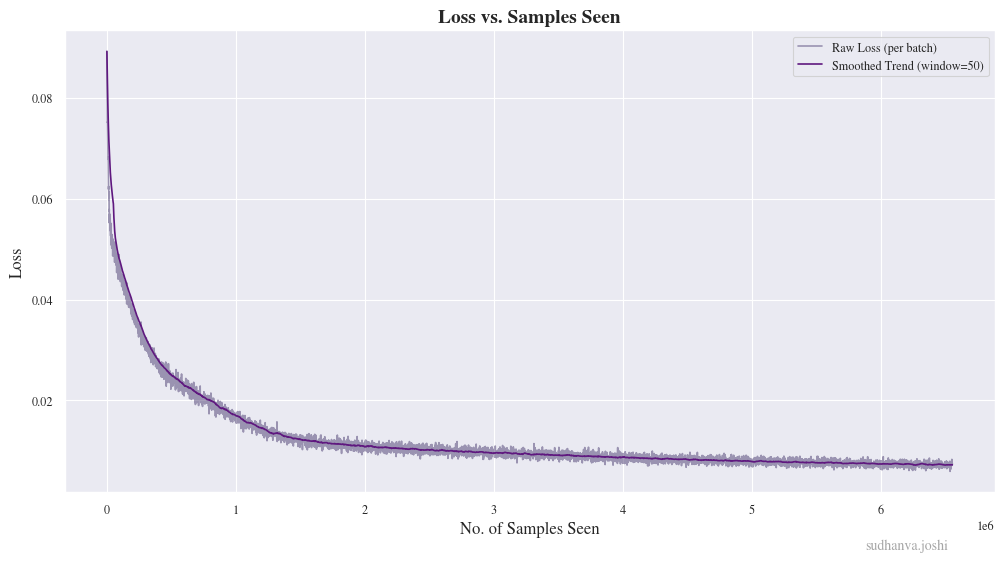

Saving final model.
Model has 17283 trainable parameters.
Final Loss: 0.007214338797111847
  - Method: Fourier
Dataloader: Fourier. Input dim: 22. Samples: 65536


Epoch 100 complete. Total samples seen: 6553600. Time: 54.83s.


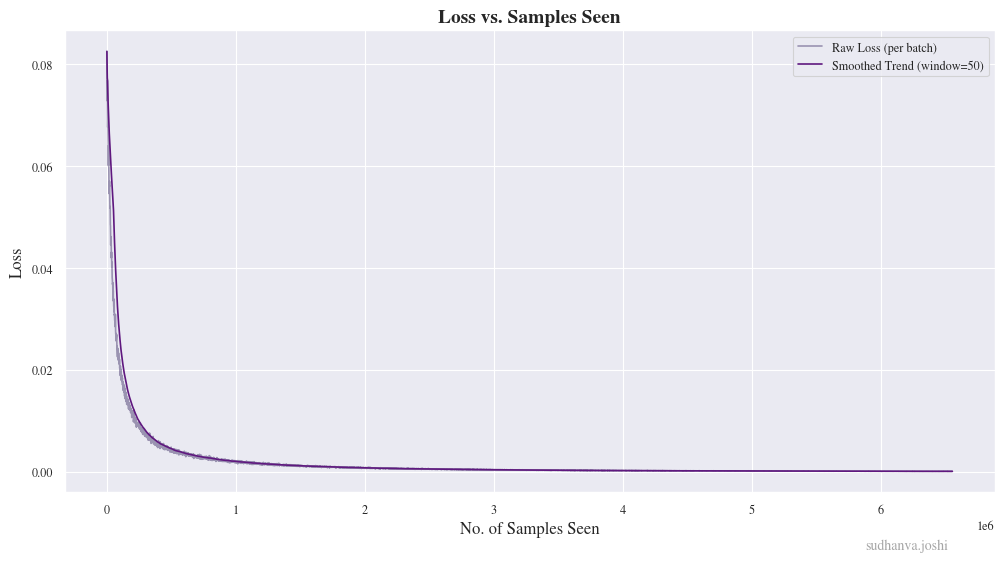

Saving final model.
Model has 19843 trainable parameters.
Final Loss: 0.000135196064361666

 Processing Blurred Image: blur_3.png
  - Method: Raw
Dataloader: Raw. Input dim: 2. Samples: 65536


Epoch 100 complete. Total samples seen: 6553600. Time: 48.43s.


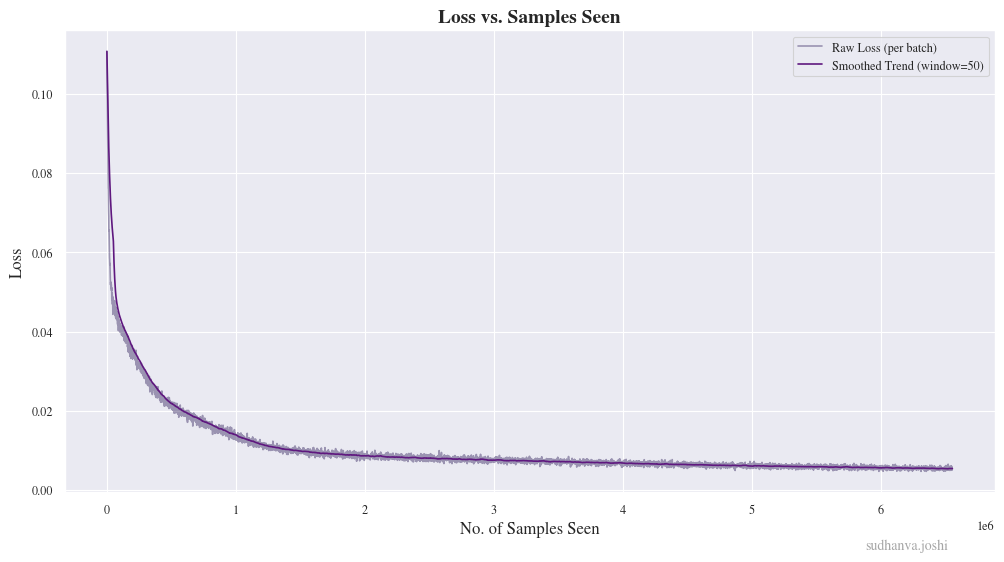

Saving final model.
Model has 17283 trainable parameters.
Final Loss: 0.005415752424063836
  - Method: Fourier
Dataloader: Fourier. Input dim: 22. Samples: 65536


Epoch 100 complete. Total samples seen: 6553600. Time: 58.82s.


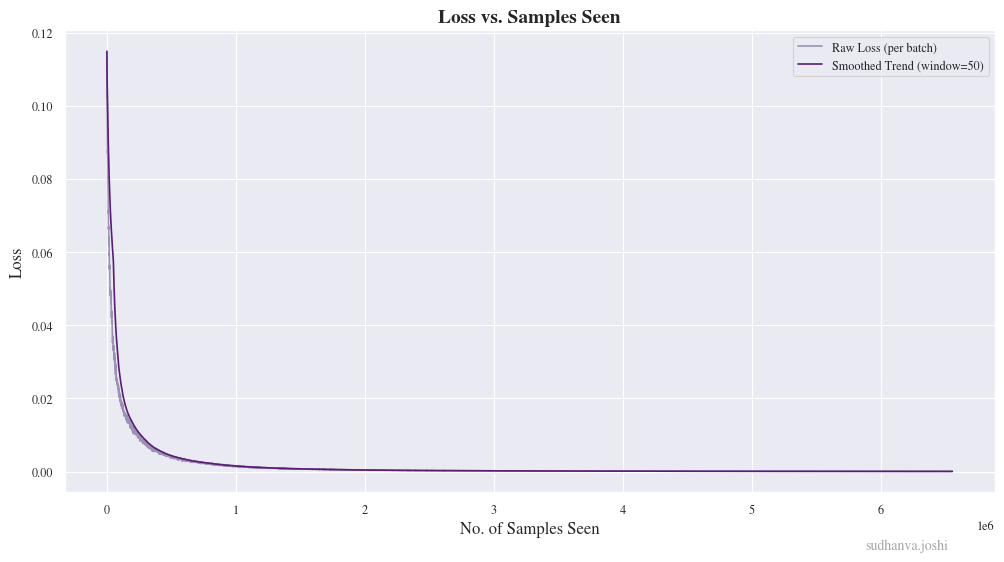

Saving final model.
Model has 19843 trainable parameters.
Final Loss: 5.0138631902481235e-05

 Processing Blurred Image: blur_4.png
  - Method: Raw
Dataloader: Raw. Input dim: 2. Samples: 65536


Epoch 100 complete. Total samples seen: 6553600. Time: 50.28s.


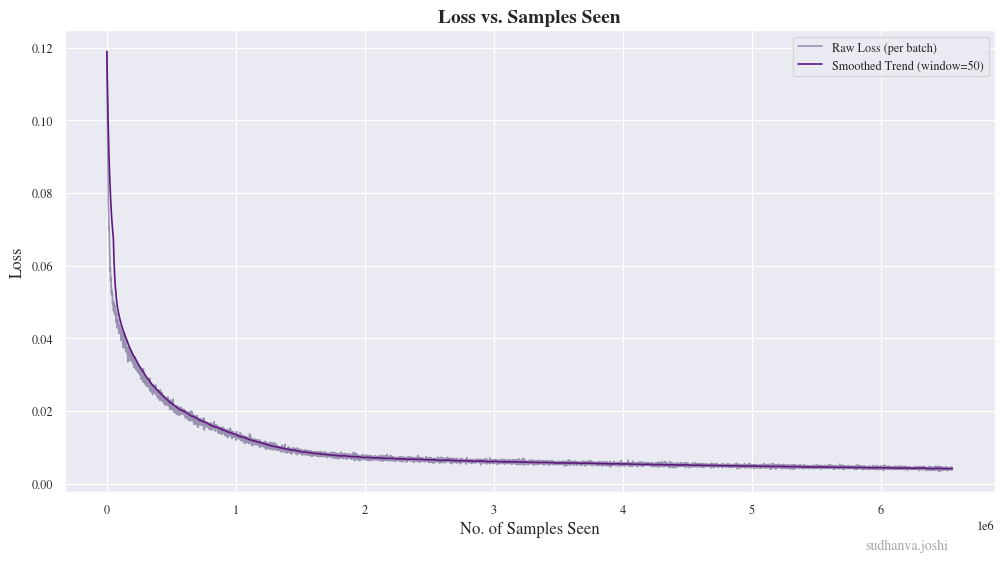

Saving final model.
Model has 17283 trainable parameters.
Final Loss: 0.004109761763037255
  - Method: Fourier
Dataloader: Fourier. Input dim: 22. Samples: 65536


Epoch 100 complete. Total samples seen: 6553600. Time: 62.60s.


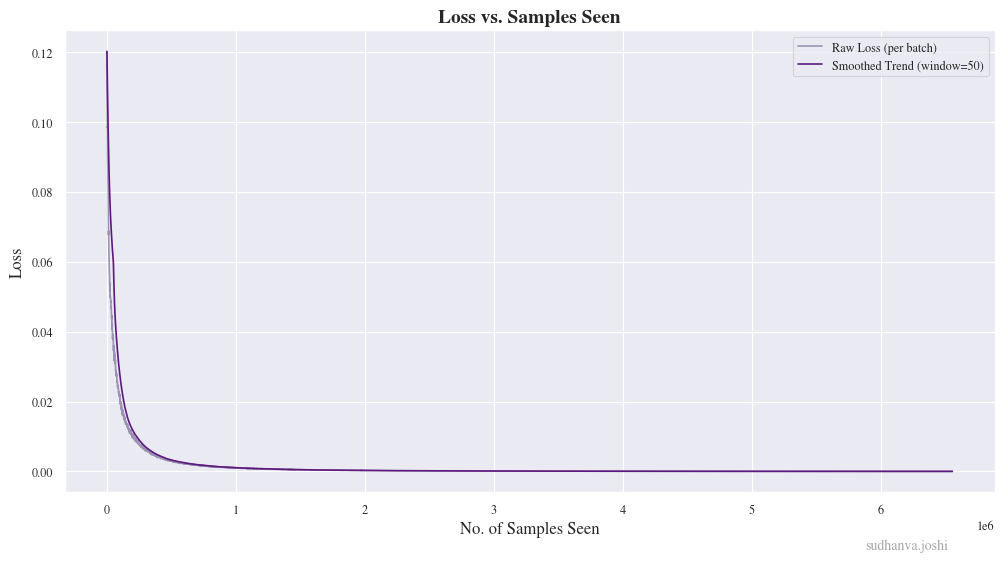

Saving final model.
Model has 19843 trainable parameters.
Final Loss: 3.0849550054846596e-05

 Processing Blurred Image: blur_5.png
  - Method: Raw
Dataloader: Raw. Input dim: 2. Samples: 65536


Epoch 100 complete. Total samples seen: 6553600. Time: 46.06s.


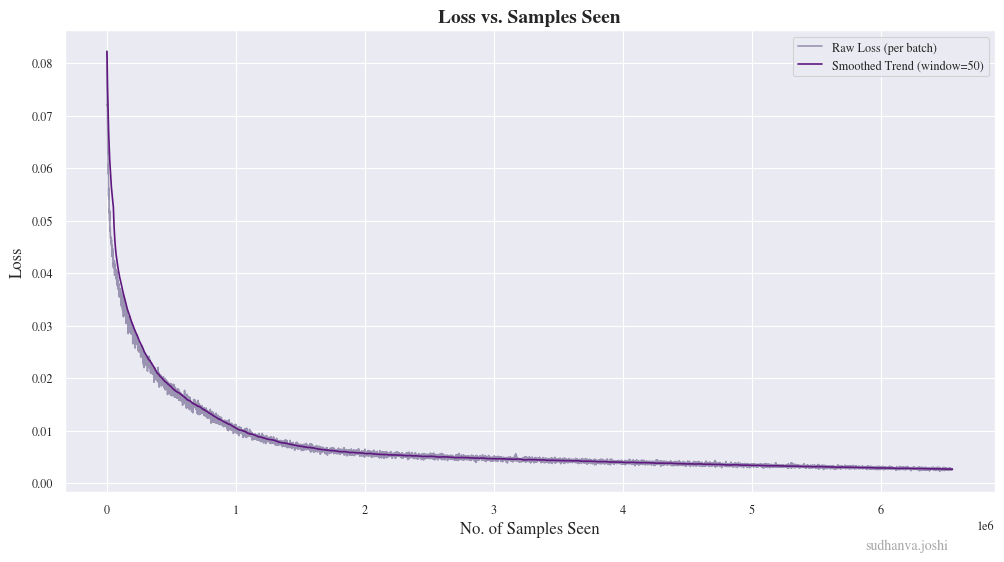

Saving final model.
Model has 17283 trainable parameters.
Final Loss: 0.0026544474479191565
  - Method: Fourier
Dataloader: Fourier. Input dim: 22. Samples: 65536


Epoch 100 complete. Total samples seen: 6553600. Time: 65.99s.


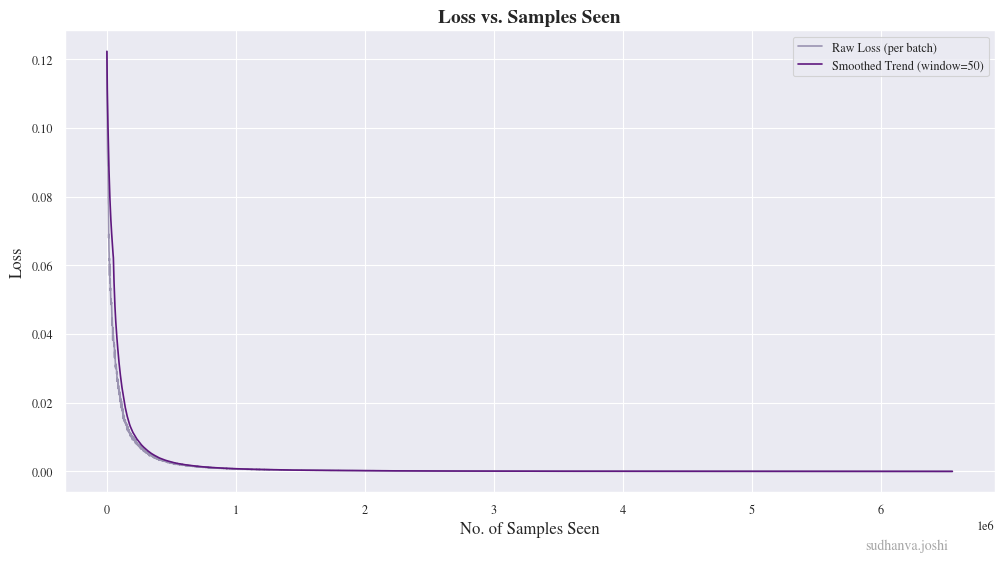

Saving final model.
Model has 19843 trainable parameters.
Final Loss: 2.1786554716538685e-05

 Processing Blurred Image: blur_6.png
  - Method: Raw
Dataloader: Raw. Input dim: 2. Samples: 65536


Epoch 100 complete. Total samples seen: 6553600. Time: 42.55s.


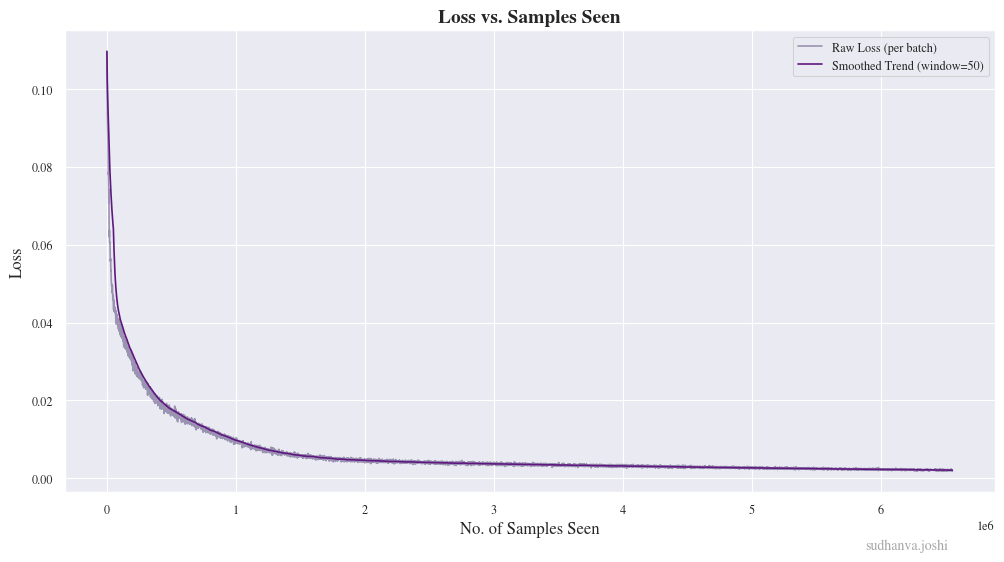

Saving final model.
Model has 17283 trainable parameters.
Final Loss: 0.002087710485016785
  - Method: Fourier
Dataloader: Fourier. Input dim: 22. Samples: 65536


Epoch 100 complete. Total samples seen: 6553600. Time: 51.07s.


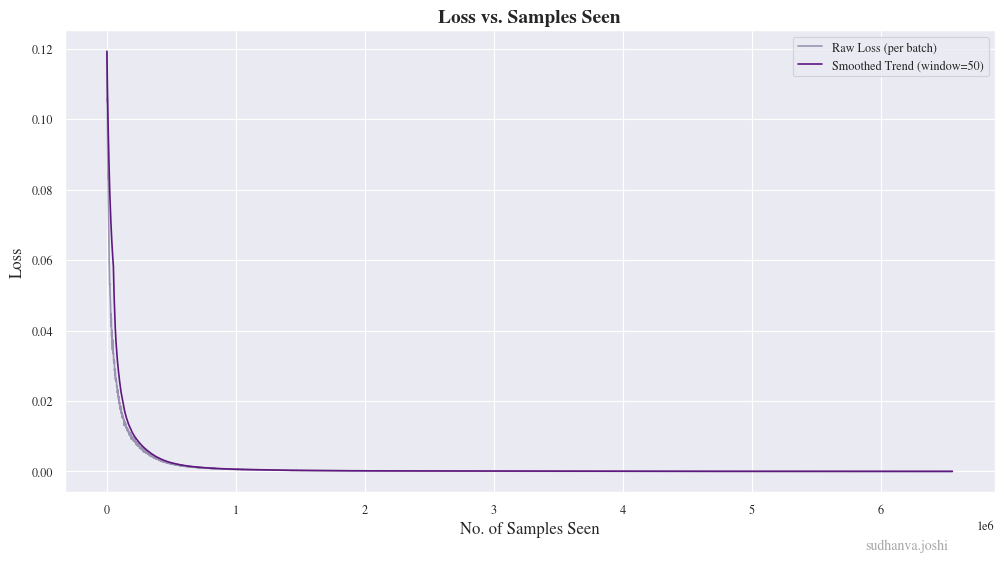

Saving final model.
Model has 19843 trainable parameters.
Final Loss: 1.859789943772337e-05

 Processing Blurred Image: blur_7.png
  - Method: Raw
Dataloader: Raw. Input dim: 2. Samples: 65536


Epoch 100 complete. Total samples seen: 6553600. Time: 46.11s.


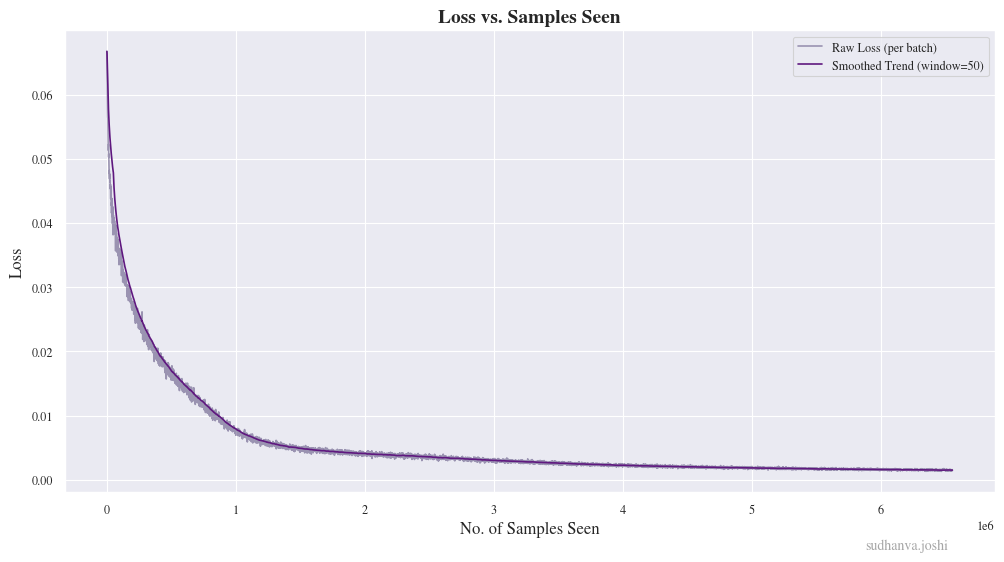

Saving final model.
Model has 17283 trainable parameters.
Final Loss: 0.0015309346606518163
  - Method: Fourier
Dataloader: Fourier. Input dim: 22. Samples: 65536


Epoch 100 complete. Total samples seen: 6553600. Time: 55.09s.


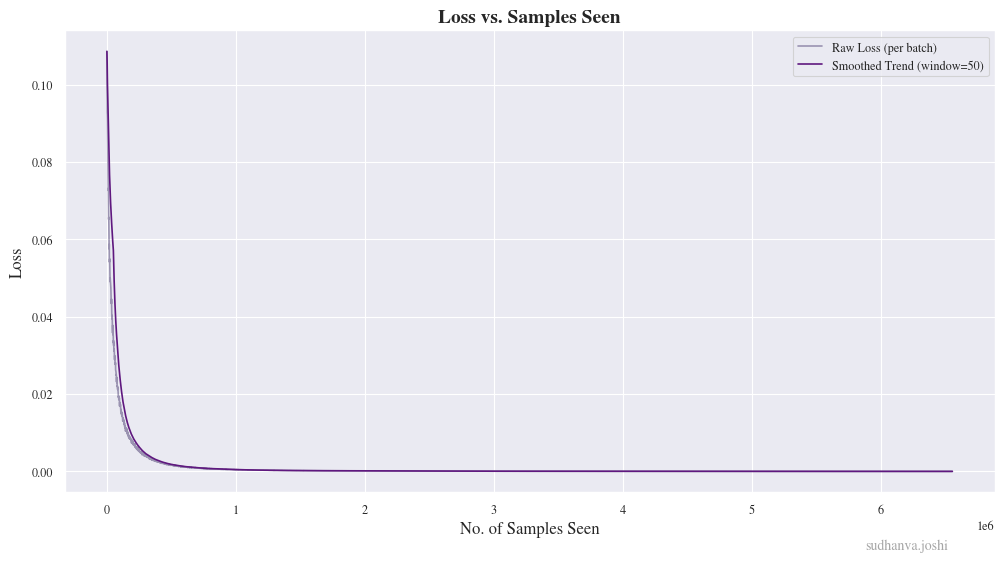

Saving final model.
Model has 19843 trainable parameters.
Final Loss: 1.5020870567830205e-05

 Processing Blurred Image: blur_8.png
  - Method: Raw
Dataloader: Raw. Input dim: 2. Samples: 65536


Epoch 100 complete. Total samples seen: 6553600. Time: 43.62s.


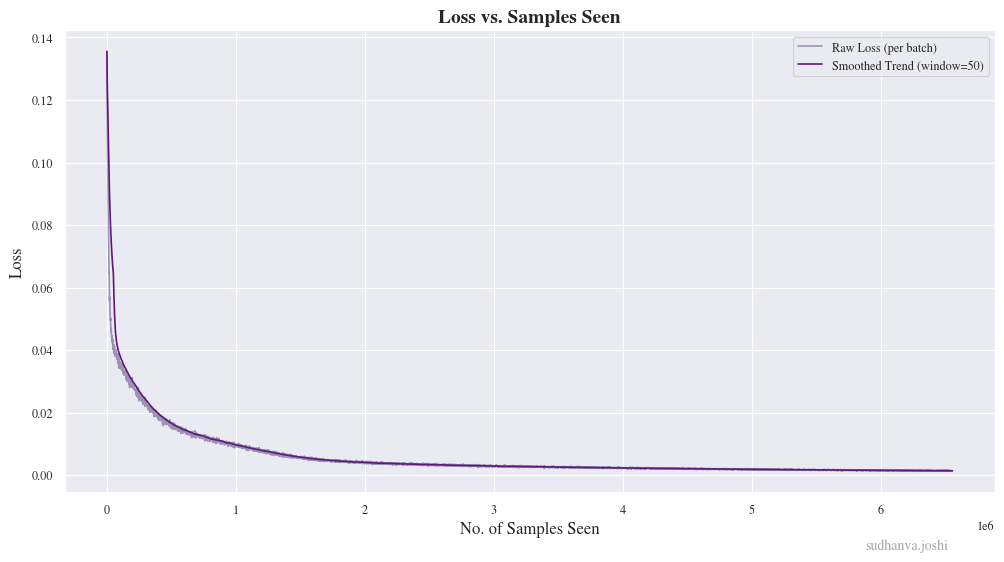

Saving final model.
Model has 17283 trainable parameters.
Final Loss: 0.001413713560069314
  - Method: Fourier
Dataloader: Fourier. Input dim: 22. Samples: 65536


Epoch 100 complete. Total samples seen: 6553600. Time: 50.22s.


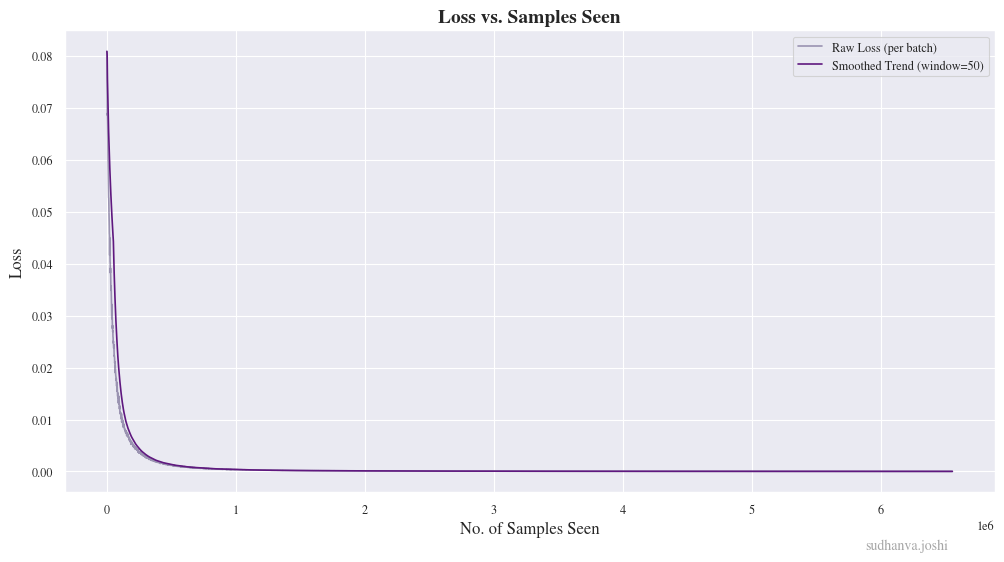

Saving final model.
Model has 19843 trainable parameters.
Final Loss: 1.328632811610256e-05

 Processing Blurred Image: blur_9.png
  - Method: Raw
Dataloader: Raw. Input dim: 2. Samples: 65536


Epoch 100 complete. Total samples seen: 6553600. Time: 45.93s.


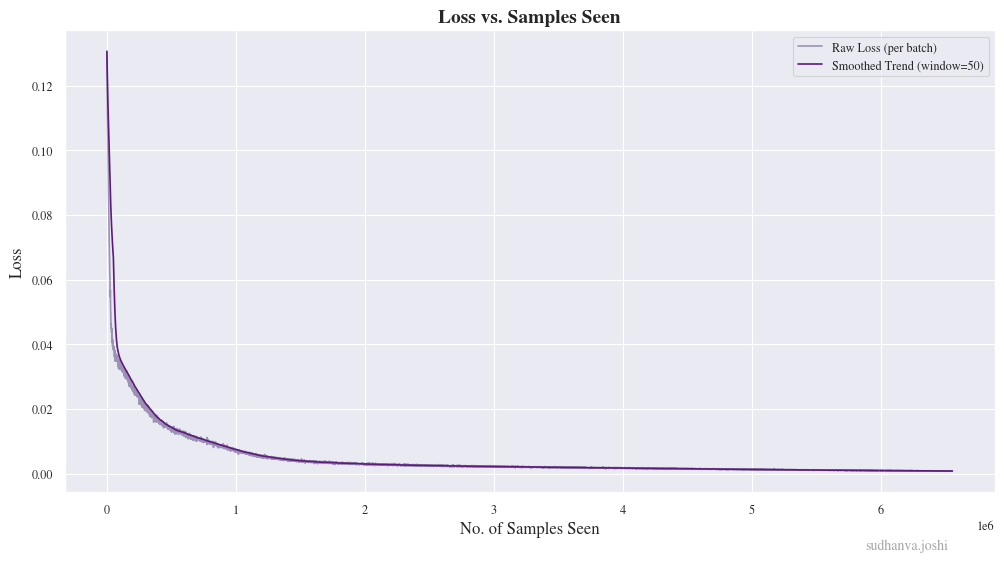

Saving final model.
Model has 17283 trainable parameters.
Final Loss: 0.0007707916455667414
  - Method: Fourier
Dataloader: Fourier. Input dim: 22. Samples: 65536


Epoch 100 complete. Total samples seen: 6553600. Time: 60.92s.


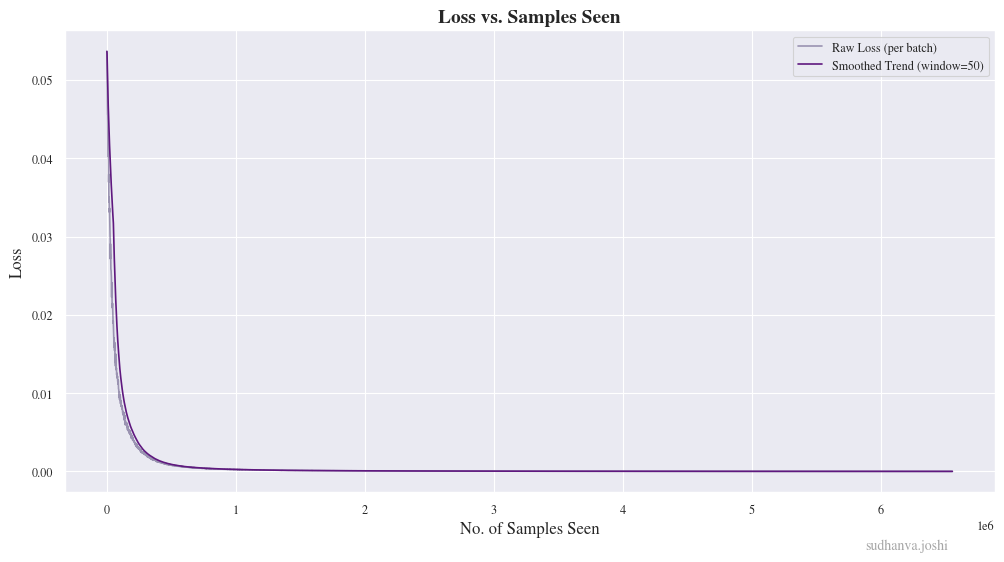

Saving final model.
Model has 19843 trainable parameters.
Final Loss: 1.1077233770681867e-05

--- Blurred Image Reconstruction Results ---
    Blur Level   Method  Final Loss
0            0     BASE    0.012888
1            0  FOURIER    0.002520
2            1     BASE    0.010084
3            1  FOURIER    0.000717
4            2     BASE    0.007214
5            2  FOURIER    0.000135
6            3     BASE    0.005416
7            3  FOURIER    0.000050
8            4     BASE    0.004110
9            4  FOURIER    0.000031
10           5     BASE    0.002654
11           5  FOURIER    0.000022
12           6     BASE    0.002088
13           6  FOURIER    0.000019
14           7     BASE    0.001531
15           7  FOURIER    0.000015
16           8     BASE    0.001414
17           8  FOURIER    0.000013
18           9     BASE    0.000771
19           9  FOURIER    0.000011


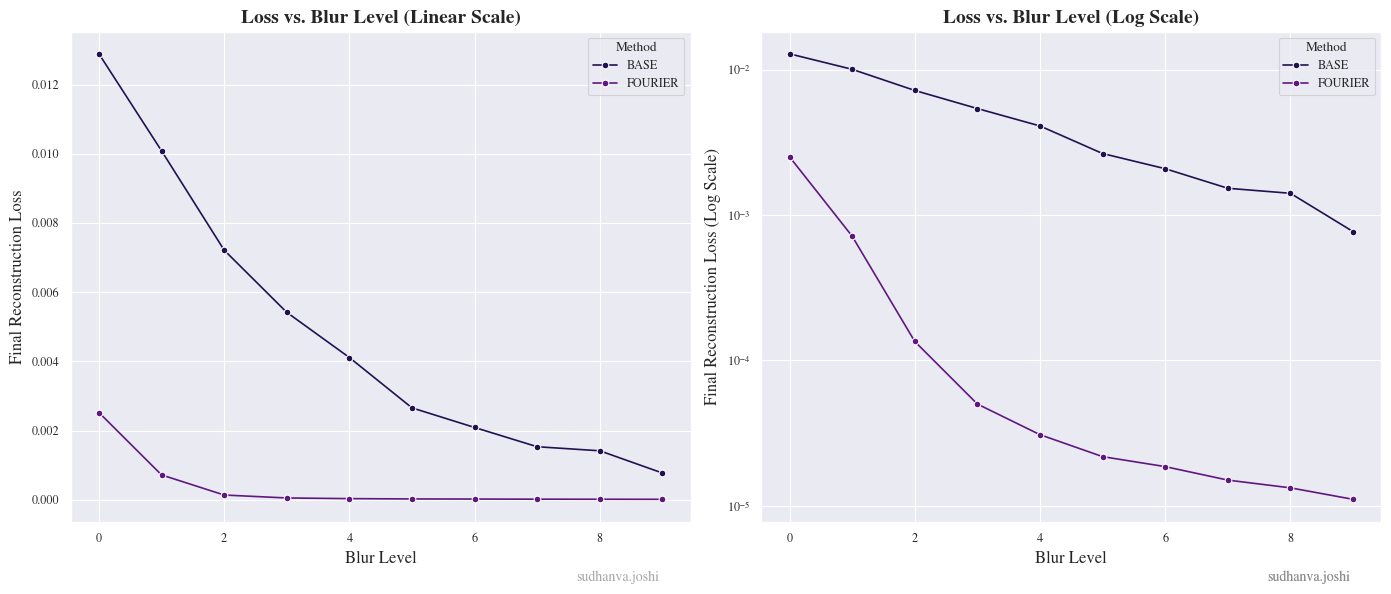

In [ ]:
blur_results = []
for blur_level in range(10):
    img_path = f"./data/Q2/blurred/blur_{blur_level}.png"
    print(f"\n Processing Blurred Image: {os.path.basename(img_path)}")
    
    for method_name, params in [('Raw', {'method': 'Raw'}), ('Fourier', {'method': 'Fourier', 'freq': 5})]:
        print(f"  - Method: {method_name}")
        dataloader = Modular_Dataloader(img_path, "RGB", **params)
        model = Model([Linear(dataloader.features.shape[1], 128, ReLU), Linear(128, 128, ReLU), Linear(128, 3, Sigmoid)])
        
        run_folder = os.path.join(artifacts_dir, f"blur_{blur_level}_{method_name}")
        _, _, _, _, epoch_losses = train_loop(
            model, dataloader, epochs=100, batch_size=BATCH_SIZE, 
            learning_rate=LEARNING_RATE, run_folder=run_folder
        )
        
        blur_results.append({
            'Blur Level': blur_level,
            'Method': 'BASE' if method_name == 'Raw' else 'FOURIER',
            'Final Loss': epoch_losses[-1] if epoch_losses else float('inf')
        })
        # Save final reconstruction for inspection
        save_reconstruction(model.predict(dataloader.features), dataloader.height, dataloader.width, 
                            os.path.join(run_folder, "final_reconstruction.png"))

blur_df = pd.DataFrame(blur_results)
print("\n Blurred Image Reconstruction Results")
print(blur_df.to_string())


plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
sns.lineplot(data=blur_df, x='Blur Level', y='Final Loss', hue='Method', marker='o')
plotinfo("Loss vs. Blur Level (Linear Scale)", "Blur Level", "Final Reconstruction Loss")
plt.legend(title='Method')

plt.subplot(1, 2, 2)
sns.lineplot(data=blur_df, x='Blur Level', y='Final Loss', hue='Method', marker='o')
plt.yscale('log')
plotinfo("Loss vs. Blur Level (Log Scale)", "Blur Level", "Final Reconstruction Loss (Log Scale)")
plt.legend(title='Method')

plt.text(0.95, -0.1, username, ha="right", va="top", 
         transform=plt.gca().transAxes, 
         fontsize=10, color="gray", alpha=0.7)
        
plt.tight_layout()
plt.show()